In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook klasörünün içinden bir üstteki veritabanına bağlanıyoruz
con = duckdb.connect("../nova.duckdb")
print("Veritabanı bağlantısı başarılı!")

Veritabanı bağlantısı başarılı!


In [4]:
raw_df = con.execute("SELECT * FROM raw_ecom_churn LIMIT 5").df()
raw_df

,Customer ID,Purchase Date,Product Category,Product Price,Quantity,Total Purchase Amount,Payment Method,Customer Age,Returns,Customer Name,Age,Gender,Churn
0,46251,2020-09-08 09:38:32,Electronics,12,3,740,Credit Card,37,0.0,Christine Hernandez,37,Male,0
1,46251,2022-03-05 12:56:35,Home,468,4,2739,PayPal,37,0.0,Christine Hernandez,37,Male,0
2,46251,2022-05-23 18:18:01,Home,288,2,3196,PayPal,37,0.0,Christine Hernandez,37,Male,0
3,46251,2020-11-12 13:13:29,Clothing,196,1,3509,PayPal,37,0.0,Christine Hernandez,37,Male,0
4,13593,2020-11-27 17:55:11,Home,449,1,3452,Credit Card,49,0.0,James Grant,49,Female,1


In [5]:
# Aynur
stg_df = con.execute("SELECT * FROM stg_ecom_customers LIMIT 5").df()
stg_df

,customer_id,customer_name,customer_age,gender,purchase_date,product_category,product_price,quantity,total_purchase_amount,payment_method,returns,is_churn
0,46251,Christine Hernandez,37,Male,2020-09-08,Electronics,12.0,3,740.0,Credit Card,0,0
1,46251,Christine Hernandez,37,Male,2022-03-05,Home,468.0,4,2739.0,PayPal,0,0
2,46251,Christine Hernandez,37,Male,2022-05-23,Home,288.0,2,3196.0,PayPal,0,0
3,46251,Christine Hernandez,37,Male,2020-11-12,Clothing,196.0,1,3509.0,PayPal,0,0
4,13593,James Grant,49,Female,2020-11-27,Home,449.0,1,3452.0,Credit Card,0,1


In [6]:
mart_df = con.execute("SELECT * FROM fct_customer_churn").df()
mart_df.head()

,purchase_id,customer_id,purchase_date,purchase_year_month,product_category,product_price,quantity,total_purchase_amount,payment_method,is_returned,customer_age,gender,is_churn,monthly_inflation_rate
0,1,1,2023-07-19,2023-07,Books,169.0,5,3491.0,PayPal,1,70,Male,0,2.297
1,2,2,2021-03-05,2021-03,Books,144.0,1,4210.0,PayPal,1,27,Female,0,2.275
2,3,2,2021-09-19,2021-09,Books,98.0,4,959.0,PayPal,0,27,Female,0,2.344
3,4,2,2022-11-21,2022-11,Electronics,178.0,3,2819.0,PayPal,0,27,Female,0,2.371
4,5,3,2020-09-27,2020-09,Electronics,402.0,2,445.0,Credit Card,0,23,Female,0,1.656


Mevcut Kolonlar: ['purchase_id', 'customer_id', 'purchase_date', 'purchase_year_month', 'product_category', 'product_price', 'quantity', 'total_purchase_amount', 'payment_method', 'is_returned', 'customer_age', 'gender', 'is_churn', 'monthly_inflation_rate']


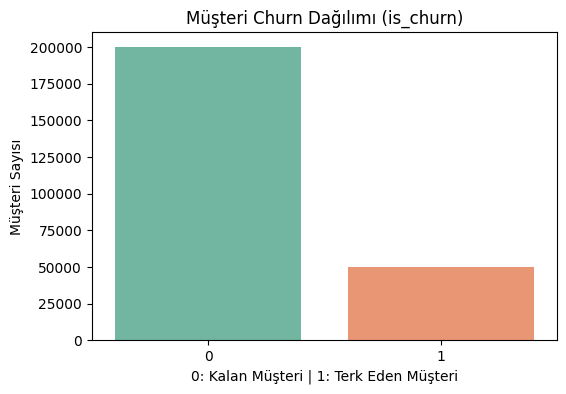

In [8]:

print("Mevcut Kolonlar:", mart_df.columns.tolist())


churn_col = [c for c in mart_df.columns if 'churn' in c.lower()][0]

plt.figure(figsize=(6, 4))
sns.countplot(data=mart_df, x=churn_col, hue=churn_col, palette='Set2', legend=False)
plt.title(f"Müşteri Churn Dağılımı ({churn_col})")
plt.xlabel("0: Kalan Müşteri | 1: Terk Eden Müşteri")
plt.ylabel("Müşteri Sayısı")
plt.show()